# Лабораторна робота № 5
## Географічні дані OpenStreetMap: від тегів до маршруту

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

**Реальне джерело:** знімок OSM XML для Чернівців, наданий через BBBike. Для відтворюваності
шари постачаються локально; швидкості першого живого запиту Overpass не виміряні.
Пішохідний граф збудовано офлайн, його двонапрямні ребра наближають OSMnx `walk`.
Обмежувальний прямокутник витягу не є офіційною адміністративною межею міста.

---

### Постановка

Ви — аналітик у туристичному застосунку. Завдання: для заданого міста
**відібрати десять найвартісніших історико-культурних об'єктів** і
**спланувати піший маршрут**, який починається на залізничному вокзалі,
обходить усі десять і повертається на вокзал.

Слово «найвартісніші» в даних не записане. Критерій ви побудуєте самі —
і захистите його.

Потім те саме для **тридцяти** об'єктів. Результат цієї, більшої задачі
стане базою порівняння в **лабораторній роботі № 8**, де ту саму задачу
розв'язуватимуть генетичним та мурашиним алгоритмами.

### Що здаєте

1. Цей ноутбук із виконаними комірками (усі виводи збережені).
2. Файл `lr5_результати.json` — результати для ЛР8.
3. Карту `lr5_маршрут.html`.
4. Звіт у кінці ноутбука: відповіді на сім питань.

### Що оцінюється

| критерій | 0 | 2 | 3 | 4 |
|---|---|---|---|---|
| Відбір об'єктів | теги взято навмання | фільтр працює | фільтр обґрунтовано | показано, що відкинуто і чому |
| Критерій рейтингу | немає | є формула | ваги пояснено | порівняно з альтернативним критерієм |
| Маршрут | не будується | будується | перевірено коректність | пояснено різницю методів числом |
| Карта | немає | точки на карті | маршрут по ребрах графа | видно різницю з прямими відрізками |
| Звіт | немає | формально | з числами | з висновком, якого не було в завданні |

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Місто підтягнеться само.

In [1]:
STUDENT_NAME = 'Єдинець Євген'
GROUP = 'ШІ-31'
LIST_NUMBER = 6

CITIES = [
    'Львів', 'Київ', 'Харків', 'Одеса', 'Дніпро',
    'Чернівці', 'Івано-Франківськ', 'Тернопіль', 'Ужгород', 'Луцьк',
    'Рівне', 'Хмельницький', 'Вінниця', 'Житомир', 'Чернігів',
    'Черкаси', 'Полтава', 'Суми', 'Кропивницький', 'Запоріжжя',
    'Миколаїв', 'Кривий Ріг', 'Кам’янець-Подільський', 'Мукачево',
    'Коломия', 'Дрогобич', 'Біла Церква', 'Ніжин', 'Остріг', 'Умань'
]
CITY = CITIES[(LIST_NUMBER - 1) % len(CITIES)] + ', Україна'
assert CITY == 'Чернівці, Україна' and LIST_NUMBER == 6
print(f'{STUDENT_NAME} · {GROUP} · варіант {LIST_NUMBER} · {CITY}')

Єдинець Євген · ШІ-31 · варіант 6 · Чернівці, Україна


> Якщо викладач призначив вам інше місто — просто перепишіть `CITY` вручну
> і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['osmnx', 'geopandas', 'shapely', 'pyproj', 'pyarrow',
            'folium', 'mapclassify', 'h3', 'networkx', 'xyzservices',
            'matplotlib', 'scipy', 'numpy', 'pandas']
missing = [p for p in REQUIRED if importlib.util.find_spec(p) is None]
if missing:
    print('Встановлення необхідних пакетів:', ', '.join(missing))
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
print('Залежності встановлено.')

Встановлення необхідних пакетів: osmnx, geopandas, shapely, pyproj, folium, mapclassify, h3
  Using cached osmnx-2.1.1-py3-none-any.whl.metadata (4.7 kB)
  Using cached geopandas-1.2.0-py3-none-any.whl.metadata (2.0 kB)
  Using cached folium-0.20.0-py2.py3-none-any.whl.metadata (4.2 kB)
  Using cached mapclassify-2.11.0-py3-none-any.whl.metadata (3.1 kB)
  Using cached pyogrio-0.13.0-cp311-abi3-macosx_12_0_arm64.whl.metadata (5.8 kB)
  Using cached branca-0.8.2-py3-none-any.whl.metadata (1.7 kB)
Using cached osmnx-2.1.1-py3-none-any.whl (104 kB)
Using cached geopandas-1.2.0-py3-none-any.whl (368 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 13.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 21.9 MB/s eta 0:00:00a 0:00:01
Using cached folium-0.20.0-py2.py3-none-any.whl (113 kB)
Using cached mapclassify-2.11.0-py3-none-any.whl (478 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 847.9/847.9 kB 13.9 MB/s eta 0:00:00
Using cached branca-0.8.2-py3-none


[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: pip3.14 install --upgrade pip


In [3]:
import warnings; warnings.filterwarnings('ignore')
import json, time, os, collections, re, unicodedata, html
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt
import folium
from scipy.spatial import cKDTree
from xyzservices import providers as xyz
from IPython.display import display

BASEMAP = xyz.Esri.WorldGrayCanvas
CRS_METRIC = 'EPSG:32635' # UTM 35N: відстані/площі в метрах для Чернівців
pd.set_option('display.width', 180)
pd.set_option('display.max_colwidth', 85)
print('geopandas',gpd.__version__, '| networkx', nx.__version__)

geopandas 1.2.0 | networkx 3.7


---
## 1. Два способи дістати дані

Робоча програма вимагає порівняти два способи доступу **за обсягом переданих
даних і за часом**:

* **живий запит** — `osmnx` питає Overpass API просто зараз;
* **знімок** — ті самі дані, збережені у файли GeoParquet, читаються з диска.

Нижче — живий запит. Запустіть його **один раз**: він збереже теку зі знімком,
і всі наступні запуски читатимуть з неї.

> Overpass — безкоштовний сервіс і обмежує частоту. Якщо запит не пройшов —
> зачекайте хвилину й повторіть. Якщо не проходить взагалі, візьміть
> резервний знімок у викладача і вкажіть це у звіті.

In [4]:
import osmnx as ox

OUT = 'osm_' + CITY.split(',')[0].strip().lower().replace(' ', '_')
os.makedirs(OUT, exist_ok=True)
ox.settings.use_cache = True
ox.settings.cache_folder = os.path.join(OUT, 'cache')
ox.settings.requests_timeout = 300
ox.settings.overpass_rate_limit = True
TOURISM_OK = ['museum', 'attraction', 'gallery', 'artwork', 'viewpoint']

def cache_bytes():
    return sum(f.stat().st_size for f in Path(ox.settings.cache_folder).glob('*.json'))

print('Тека даних:', os.path.abspath(OUT))
print('Якщо шари .parquet уже в цій теці, запити не виконуватимуться.')

Тека даних: /Users/yevhenyedynets/Desktop/ІАВД/Lab5/osm_чернівці
Якщо шари .parquet уже в цій теці, запити не виконуватимуться.


### Дві налаштовані дрібниці, без яких запит не пройде

Це не формальності — кожна з них ламає збір по-своєму, і жодна не схожа
на свою справжню причину.

**Представитись.** Overpass відповідає **HTTP 406** клієнтові, який прийшов
із типовим заголовком `python-requests`. `osmnx` надсилає свій `User-Agent`
сам, але якщо ви звертаєтесь до сервісу напряму — надсилайте теж.
Рядок має бути **лише латиницею**: HTTP-заголовки передаються в latin-1,
і кирилиця кладе запит помилкою `UnicodeEncodeError` ще до відправлення.

**Обрати машину.** За іменем `overpass-api.de` стоїть кілька серверів, і
частина з них відмовляє у з’єднанні. `osmnx` закріплює одну адресу на
всю сесію — навмисно, щоб не порушувати облік слотів. Якщо закріпиться та,
що відмовляє, впаде весь збір. Тому адресу обираємо самі, вже перевірену.

In [5]:
import socket
USER_AGENT = ('LvivPolytechnic-SK26-coursework/1.0 '
              '(https://lpnu.ua; student lab assignment)')
assert USER_AGENT.isascii()
ox.settings.http_user_agent = USER_AGENT

# Ніяких мережевих перевірок при роботі зі знімком. Для нового завантаження
# використовуємо стандартний DNS/retry OSMnx або окремий fetch_city_osm.py.
def pin_working_ip(hostname='overpass-api.de', port=443, timeout=4):
    try:
        addr = socket.getaddrinfo(hostname,port,socket.AF_INET,socket.SOCK_STREAM)
        ips = sorted({a[4][0] for a in addr})
    except OSError:
        return None
    for ip in ips:
        s=socket.socket(); s.settimeout(timeout)
        try:
            s.connect((ip,port))
            base=socket.gethostbyname
            socket.gethostbyname = lambda h, old=base, good=ip: good if h==hostname else old(h)
            return ip
        except OSError:
            pass
        finally:
            s.close()
    return None

needed = ('boundary.parquet', 'heritage.parquet', 'stations.parquet',
          'amenities.parquet', 'road_nodes.parquet', 'road_edges.parquet')
missing_layers = [f for f in needed if not (Path(OUT)/f).is_file()]
if missing_layers:
    print('Відсутні шари:', missing_layers)
    print('Для надійнішого початкового збору: python fetch_city_osm.py "Чернівці, Україна" --no-buildings')
    print('Перевіряю сервер Overpass:', pin_working_ip() or 'без зафіксованого IP')
else:
    print('Повний знімок на диску. Мережевий доступ не потрібен.')

Повний знімок на диску. Мережевий доступ не потрібен.


> Якщо жодна машина не відповіла — виконайте комірку ще раз за хвилину,
> або візьміть у викладача резервний знімок і зазначте це у звіті.
> Інші дзеркала перелічені на сторінці
> [Overpass API](https://wiki.openstreetmap.org/wiki/Overpass_API);
> адресу можна підставити у `ox.settings.overpass_url`.

### Завдання 1.1

Допишіть функцію `fetch`: вона має зберегти шар у `.parquet`, а якщо файл
уже є — прочитати його, **не звертаючись до мережі**. Поверніть також,
скільки МБ пішло мережею і скільки секунд це зайняло.

Підказка щодо `clean`: у OSM одна колонка може містити і число, і список
(ребро, склеєне з кількох шляхів). Parquet вимагає один тип на колонку,
тому неоднорідну колонку треба звести до тексту **цілком**.

In [6]:
from pandas.api.types import is_object_dtype

def clean(gdf):
    """Нормалізація OSM-атрибутів перед GeoParquet (збереження геометрії/CRS)."""
    g = gdf.reset_index()
    for col in g.columns:
        if col == 'geometry':
            continue
        has_container = g[col].map(lambda v: isinstance(v, (list,dict,set,tuple))).any()
        if has_container or is_object_dtype(g[col].dtype):
            def as_str(v):
                if v is None or (not isinstance(v,(list,dict,set,tuple)) and pd.isna(v)):
                    return None
                if isinstance(v,set):
                    v=sorted(v,key=str)
                if isinstance(v,(list,dict,tuple)):
                    return json.dumps(v,ensure_ascii=False,default=str)
                return str(v)
            g[col]=g[col].map(as_str).astype('string')
    return g

COST = {}
COST_HISTORY_PATH = Path(OUT)/'lr5_live_cost.json'
if COST_HISTORY_PATH.exists():
    LIVE_COST = json.loads(COST_HISTORY_PATH.read_text('utf-8'))
else:
    LIVE_COST = {}

def record_live(name, info):
    LIVE_COST[name] = info
    COST_HISTORY_PATH.write_text(json.dumps(LIVE_COST,ensure_ascii=False,indent=2),encoding='utf-8')

def fetch(name,getter):
    path=Path(OUT)/(name+'.parquet')
    if path.exists() and path.stat().st_size:
        t0=time.perf_counter()
        g=gpd.read_parquet(path)
        COST[name]={'спосіб':'знімок','записів':len(g),'передано_МБ':0.0,
                    'файл_МБ':round(path.stat().st_size/1e6,3),
                    'секунд':round(time.perf_counter()-t0,3)}
        return g
    t0=time.perf_counter(); before=cache_bytes()
    try:
        g=clean(getter())
    except Exception as e:
        raise RuntimeError(f'Не вдалось одержати OSM-шар {name!r}. '
                           f'Спробуйте fetch_city_osm.py або надайте знімок. Причина: {e}') from e
    g.to_parquet(path,index=False)
    info={'спосіб':'живий запит','записів':len(g),
          'передано_МБ':round(max(0,cache_bytes()-before)/1e6,3),
          'файл_МБ':round(path.stat().st_size/1e6,3),
          'секунд':round(time.perf_counter()-t0,3)}
    COST[name]=info
    record_live(name,info)
    return g

In [7]:
boundary = fetch('boundary',lambda: ox.geocode_to_gdf(CITY))
assert len(boundary) > 0 and boundary.crs is not None
poly = boundary.geometry.iloc[0]
print('Місто:',CITY,'| площа межі %.1f км²' % (boundary.to_crs(CRS_METRIC).area.iloc[0]/1e6))

Місто: Чернівці, Україна | площа межі 285.6 км²


In [8]:
heritage = fetch('heritage', lambda: ox.features_from_polygon(
    poly, {'historic': True, 'tourism': TOURISM_OK}))
stations = fetch('stations', lambda: ox.features_from_polygon(
    poly, {'railway': ['station', 'halt'], 'building': ['train_station']}))
amenities = fetch('amenities', lambda: ox.features_from_polygon(
    poly, {'amenity': ['cafe', 'restaurant', 'drinking_water', 'toilets']}))

NODES_P=Path(OUT)/'road_nodes.parquet'
EDGES_P=Path(OUT)/'road_edges.parquet'
if NODES_P.is_file() and EDGES_P.is_file() and NODES_P.stat().st_size and EDGES_P.stat().st_size:
    t0=time.perf_counter()
    nodes,edges=gpd.read_parquet(NODES_P),gpd.read_parquet(EDGES_P)
    COST['мережа walk']={'спосіб':'знімок','записів':len(nodes)+len(edges),
                        'передано_МБ':0.0,'файл_МБ':round((NODES_P.stat().st_size+EDGES_P.stat().st_size)/1e6,3),
                        'секунд':round(time.perf_counter()-t0,3)}
else:
    t0=time.perf_counter(); before=cache_bytes()
    G_raw=ox.graph_from_polygon(poly,network_type='walk')
    nodes_raw,edges_raw=ox.convert.graph_to_gdfs(G_raw)
    clean(nodes_raw).to_parquet(NODES_P,index=False)
    clean(edges_raw).to_parquet(EDGES_P,index=False)
    nodes,edges=gpd.read_parquet(NODES_P),gpd.read_parquet(EDGES_P)
    info={'спосіб':'живий запит','записів':len(nodes)+len(edges),
          'передано_МБ':round(max(0,cache_bytes()-before)/1e6,3),
          'файл_МБ':round((NODES_P.stat().st_size+EDGES_P.stat().st_size)/1e6,3),
          'секунд':round(time.perf_counter()-t0,3)}
    COST['мережа walk']=info
    record_live('мережа walk',info)
assert {'osmid','x','y'}.issubset(nodes.columns)
assert {'u','v','length'}.issubset(edges.columns)
print('Пішохідна мережа: вузлів %d | ребер %d' % (len(nodes),len(edges)))

Пішохідна мережа: вузлів 52730 | ребер 114740


### Завдання 1.2

Зведіть `COST` у таблицю і дайте відповідь у звіті: **у скільки разів
читання знімка швидше за живий запит** і **скільки мегабайтів ви не передали
мережею** при повторному запуску.

Контрольна ознака правильності: при **другому** запуску ноутбука всі рядки
мають мати спосіб «знімок», а `передано_МБ` — нуль.

In [9]:
cost_table=pd.DataFrame(COST).T
display(cost_table)
# Результат попереднього мережевого завантаження береться із журналу або
# manifest.json від fetch_city_osm.py; не видаємо ці цифри за новий запит.
manifest_path=Path(OUT)/'manifest.json'
manifest=json.loads(manifest_path.read_text('utf-8')) if manifest_path.exists() else {}
if manifest:
    assert 'чернівці' in str(manifest.get('_місце',CITY)).casefold(), 'Сторонній знімок міста!'
    assert manifest.get('_мережа','walk') == 'walk', 'Знімок не пішохідний!'

history = dict(LIVE_COST)
SOURCE_OFFLINE = 'BBBike' in manifest.get('_джерело', '')
if SOURCE_OFFLINE:
    print('Знімок з BBBike OSM XML: час живого Overpass-запиту НЕ вимірювався.')
else:
    for name in list(COST.keys()):
        if name not in history and name in manifest:
            x=manifest[name]
            history[name]={'спосіб':'живий запит (manifest)',
                           'записів':x.get('записів'), 'передано_МБ':x.get('передано_МБ'),
                           'файл_МБ':x.get('файл_МБ'),'секунд':x.get('секунд')}
    if 'мережа walk' not in history and 'road_nodes' in manifest and 'road_edges' in manifest:
        x,y=manifest['road_nodes'],manifest['road_edges']
        if x.get('секунд') is not None and y.get('секунд') is not None:
            history['мережа walk']={'спосіб':'живий запит (manifest)',
                'передано_МБ':None, 'секунд':x['секунд']+y['секунд']}

comparison=[]
for name,c in COST.items():
    h=history.get(name)
    if h and h.get('секунд') is not None and c['спосіб']=='знімок':
        ratio=float(h['секунд']) / max(1e-9,c['секунд'])
        comparison.append({'шар':name,'живий, с':h['секунд'],
                           'знімок, с':c['секунд'],'прискорення, разів':round(ratio,1),
                           'економія трафіку, МБ':h.get('передано_МБ')})
if comparison:
    display(pd.DataFrame(comparison))
else:
    print('Для порівняння потрібен журнал попереднього живого запиту; дані повторного читання зафіксовані.')
assert all(x['передано_МБ']==0 for x in COST.values() if x['спосіб']=='знімок')

,спосіб,записів,передано_МБ,файл_МБ,секунд
boundary,знімок,1,0.0,0.008,0.191
heritage,знімок,93,0.0,0.029,0.013
stations,знімок,16,0.0,0.02,0.012
amenities,знімок,452,0.0,0.04,0.012
мережа walk,знімок,167470,0.0,5.724,0.061


Знімок з BBBike OSM XML: час живого Overpass-запиту НЕ вимірювався.
Для порівняння потрібен журнал попереднього живого запиту; дані повторного читання зафіксовані.


> **Чому пішохідна мережа, а не автомобільна.** У старому місті музеї стоять
> за сотню метрів один від одного, а автомобільних вузлів там одиниці. Кілька
> пам'яток сядуть на **один** вузол графа, і матриця віддалей скаже, що між
> ними нуль метрів. Задача розв'яжеться, відповідь буде неправильною, і
> повідомлення про помилку не з'явиться. У кроці 4 ви це перевірите явно.

---
## 2. Хто претендує на звання пам'ятки

У OpenStreetMap немає тега «визначна пам'ятка». Є два сімейства:

* `historic=*` — `castle`, `church`, `monument`, `memorial`, `ruins`, `tower`, `yes`…
* `tourism=*` — `museum`, `gallery`, `attraction`, `artwork`, `viewpoint`

Перетин неповний: музей у сучасній будівлі має лише `tourism`, руїни фортеці —
лише `historic`. Тому беремо **об'єднання**.

📖 <https://wiki.openstreetmap.org/wiki/Map_Features>

### Завдання 2.1

Відберіть кандидатів і **назвіть у звіті, скільки об'єктів ви відкинули й чому**.

In [10]:
def col_as_str(df,name):
    return df[name].astype('string') if name in df.columns else pd.Series(pd.NA,index=df.index,dtype='string')

historic_col=col_as_str(heritage,'historic')
tourism_col=col_as_str(heritage,'tourism')
name_col=col_as_str(heritage,'name')
mask_hist=historic_col.notna() & ~historic_col.str.lower().isin(['no','false','0']).fillna(False)
mask_tour=tourism_col.isin(TOURISM_OK).fillna(False)
mask=mask_hist | mask_tour
valid_name=name_col.notna() & name_col.str.strip().ne('').fillna(False)
valid_geom=heritage.geometry.notna() & ~heritage.geometry.is_empty
cand=heritage.loc[mask & valid_name & valid_geom].copy().reset_index(drop=True)
assert len(cand)>=10, f'Замало названих пам’яток: {len(cand)}'
if 'osm_type' in cand.columns and 'osmid' in cand.columns:
    cand['osm_key']=cand['osm_type'].astype(str)+'/'+cand['osmid'].astype(str)
else:
    cand['osm_key']=cand.index.astype(str)
FILTER_STATS={'загалом':len(heritage),'відповідають_тегам':int(mask.sum()),
              'без_потрібних_тегів':int((~mask).sum()),
              'без_назви_або_геометрії':int((mask & ~(valid_name&valid_geom)).sum()),
              'залишилось':len(cand)}
print(FILTER_STATS)
print('Типи геометрії:',cand.geometry.geom_type.value_counts().to_dict())

{'загалом': 93, 'відповідають_тегам': 93, 'без_потрібних_тегів': 0, 'без_назви_або_геометрії': 21, 'залишилось': 72}
Типи геометрії: {'Point': 68, 'Polygon': 4}


In [11]:
print('=== historic ===')
print(col_as_str(cand,'historic').value_counts().head(10).to_string())
print('\n=== tourism ===')
print(col_as_str(cand,'tourism').value_counts().head(10).to_string())
print('\nГеометрія:',cand.geometry.geom_type.value_counts().to_dict())
if not any(t in set(cand.geometry.geom_type) for t in ('Point','MultiPoint')):
    print('Увага: у вибірці немає Point — перевірте джерело та фільтр.')

=== historic ===
historic
memorial          32
monument           6
castle             1
church             1
wayside_shrine     1

=== tourism ===
tourism
museum        12
attraction    12
artwork        4
viewpoint      3
gallery        1

Геометрія: {'Point': 68, 'Polygon': 4}


> **Перевірте себе.** Серед типів геометрії мають бути і `Point`, і `Polygon`.
> Якщо самі лише полігони — ви відфільтрували зайве: пам'ятники, меморіали та
> оглядові точки в OSM є **вузлами**, у них немає будівлі.

### Якщо кандидатів менше тридцяти

Невелике місто може дати 15–20 об'єктів. Тоді:

1. розширте перелік `tourism` (наприклад, додайте `theatre`, `place_of_worship`);
2. або зменште `N_LARGE` до того, що є;

і **обов'язково зазначте це у звіті** разом із числом.

---
## 3. Критерій «найкращі»

Ключовий крок роботи. Стовпця «цінність» у даних немає. Його треба
сконструювати і захистити.

Сигнали, які є в OSM:

| сигнал | що означає |
|---|---|
| `wikidata` / `wikipedia` | про об'єкт є стаття — хтось сторонній визнав його вартим опису |
| кількість колонок `name:*` | назву переклали N мовами — перекладають те, що шукають іноземці |
| `tourism=museum/gallery` | призначений для відвідування |
| `historic` заповнений | має історичну природу |
| площа полігона | розмір — **найслабший сигнал**: великим буває і склад |

### Завдання 3.1

Побудуйте числовий рейтинг. Вимоги:

* використати **щонайменше три** різні сигнали;
* звести різнорідні величини до спільної шкали (підказка: `rank(pct=True)`);
* **пояснити у звіті, чому саме такі ваги**.

In [12]:
metric=cand.to_crs(CRS_METRIC)
cand['area_m2']=np.where(metric.geometry.geom_type.isin(['Polygon','MultiPolygon']),
                            metric.geometry.area.to_numpy(),0.0)
wiki1=col_as_str(cand,'wikidata').str.strip().fillna('')
wiki2=col_as_str(cand,'wikipedia').str.strip().fillna('')
cand['wiki']=((wiki1!='') | (wiki2!='')).astype(int)
cand['wiki_id']=wiki1
lang_cols=[c for c in cand.columns if str(c).startswith('name:')]
cand['n_lang']=cand[lang_cols].notna().sum(axis=1) if lang_cols else 0
cand['museum_gallery']=col_as_str(cand,'tourism').isin(['museum','gallery']).fillna(False).astype(int)
cand['historic_flag']=mask_hist.loc[heritage.loc[mask & valid_name & valid_geom].index].to_numpy(dtype=int)
# Rank(pct=True) з однаковим масштабом 0..1; для відсутнього сигналу лишаємо 0.
lang_scaled=cand['n_lang'].rank(pct=True).where(cand['n_lang']>0,0.0)
area_scaled=cand['area_m2'].rank(pct=True).where(cand['area_m2']>0,0.0)
WEIGHTS={'wiki':0.35,'мови':0.25,'museum_gallery':0.15,'historic':0.20,'площа':0.05}
assert abs(sum(WEIGHTS.values())-1)<1e-9
cand['score']=(WEIGHTS['wiki']*cand['wiki']+
               WEIGHTS['мови']*lang_scaled+
               WEIGHTS['museum_gallery']*cand['museum_gallery']+
               WEIGHTS['historic']*cand['historic_flag']+
               WEIGHTS['площа']*area_scaled)
print('Кандидатів:',len(cand),'| з Wikidata/Wikipedia:',cand['wiki'].sum(),
      '| багатомовних назв:',(cand['n_lang']>0).sum())
display(cand[['name','wiki','n_lang','historic_flag','museum_gallery','area_m2','score']]
        .sort_values('score',ascending=False).head(12))

Кандидатів: 72 | з Wikidata/Wikipedia: 7 | багатомовних назв: 72


,name,wiki,n_lang,historic_flag,museum_gallery,area_m2,score
68,Костел Воздвиження Святого Христа,1,3,1,0,1114.559417,0.837847
17,Музей Володимира Івасюка,1,2,0,1,0.000000,0.706597
24,Пам'ятник Сидору Воробкевичу,1,1,1,0,0.000000,0.643750
18,Franz Josef,1,1,1,0,0.000000,0.643750
69,Музей Буковинської Діаспори,1,1,0,1,473.020355,0.643056
41,Музей пожежно-рятувальної справи,1,1,0,1,0.000000,0.593750
70,Турецька криниця,1,1,0,0,84.816966,0.491667
36,Зельма Меербаум-Айзінґер,0,3,1,0,0.000000,0.437847
15,Пам'ятник Йозефу Главці,0,3,1,0,0.000000,0.437847
42,Іван Котляревський,0,2,1,0,0.000000,0.406597


### Завдання 3.2 — обов'язкове порівняння

Побудуйте **другий** рейтинг за найпростішим критерієм — площею будівлі —
і порахуйте, скільки об'єктів збігається в перших десяти.

Це головне питання роботи: обидва списки отримані з тих самих даних, тим
самим кодом, без жодної помилки. Якщо вони різні — поясніть у звіті, що це
означає для слова «найкращі».

In [13]:
N_SMALL, N_LARGE=10,30

def normalize_name(s):
    s=unicodedata.normalize('NFKC',str(s)).casefold()
    return ' '.join(re.findall(r'\w+',s))

ranked=cand.sort_values(['score','osm_key'],ascending=[False,True]).reset_index(drop=True)
# Виявляємо явні дублікати по всій вибірці, щоб добрати 30 різних об'єктів:
# збіг Wikidata-ID або тієї самої нормалізованої назви в радіусі 60 м.
rp=ranked.to_crs(CRS_METRIC).geometry.representative_point()
xy=np.column_stack((rp.x.to_numpy(),rp.y.to_numpy()))
pairs=cKDTree(xy).query_pairs(r=60)
dropped=set(); duplicate_log=[]
for i,j in sorted(pairs,key=lambda p:(max(p),min(p))):
    if i in dropped or j in dropped: continue
    w1,w2=ranked.iloc[i],ranked.iloc[j]
    eq_wiki=bool(w1['wiki_id'] and w2['wiki_id'] and w1['wiki_id']==w2['wiki_id'])
    eq_name=normalize_name(w1['name']) == normalize_name(w2['name'])
    if eq_wiki or eq_name:
        keep,drop=sorted([i,j]) # впорядковано за рейтингом
        dropped.add(drop)
        duplicate_log.append((str(ranked.iloc[keep]['name']),str(ranked.iloc[drop]['name']),
                              'Wikidata' if eq_wiki else 'однакова назва'))
ranked_clean=ranked.drop(index=list(dropped)).reset_index(drop=True)
N_LARGE=min(N_LARGE,len(ranked_clean))
assert N_LARGE>=N_SMALL,'Не вистачає 10 різних пам’яток'
if N_LARGE!=30: print('УВАГА: кандидатів менше 30. Велика задача матиме',N_LARGE,'об’єктів.')
top_score=ranked_clean.head(N_LARGE).copy().reset_index(drop=True)
top10=top_score.head(N_SMALL).copy()
top_naive=ranked_clean.sort_values(['area_m2','osm_key'],ascending=[False,True]).head(N_SMALL)
overlap=len(set(top10['osm_key']) & set(top_naive['osm_key']))
print('Явних дублікатів відкинуто:',len(duplicate_log))
print('Збіг рейтингів:',overlap,'із',N_SMALL)
display(pd.DataFrame({'комплексний рейтинг':top10['name'].to_list(),
                      'лише площа':top_naive['name'].to_list()}))

Явних дублікатів відкинуто: 1
Збіг рейтингів: 3 із 10


,комплексний рейтинг,лише площа
0,Костел Воздвиження Святого Христа,Костел Воздвиження Святого Христа
1,Музей Володимира Івасюка,Музей Буковинської Діаспори
2,Franz Josef,Церква Покрови Пресвятої Діви Марії
3,Пам'ятник Сидору Воробкевичу,Турецька криниця
4,Музей Буковинської Діаспори,Пам’ятник загиблим в Афганістані
5,Музей пожежно-рятувальної справи,Пам'ятник Юрію Федьковичу
6,Турецька криниця,Козацький пагорб
7,Пам'ятник Йозефу Главці,Краєзнавчий музей
8,Зельма Меербаум-Айзінґер,Пам'ятник Т.Г.Шевченку
9,Паротяг 159-495,Пам'ятник Францу Йосифу Першому


### Завдання 3.3 — дублікати

OSM наповнюють різні люди. Той самий музей трапляється двічі під різними
назвами, а вежа буває окремим об'єктом усередині палацу. Знайдіть у `top_score`
пари, що стоять ближче **60 метрів** одна до одної, і вирішіть, що з ними робити.

Рішення (лишити / злити / видалити) опишіть у звіті.

In [14]:
def close_pairs(gdf,limit_m=60):
    p=gdf.to_crs(CRS_METRIC).geometry.representative_point()
    xy=np.column_stack([p.x.to_numpy(),p.y.to_numpy()])
    return sorted([(i,j,float(np.linalg.norm(xy[i]-xy[j])))
                   for i,j in cKDTree(xy).query_pairs(limit_m)],key=lambda t:t[2])
close=close_pairs(top_score)
near_rows=[]
for i,j,d in close:
    a,b=top_score.iloc[i],top_score.iloc[j]
    duplicate=(normalize_name(a['name'])==normalize_name(b['name']) or
               bool(a['wiki_id'] and b['wiki_id'] and a['wiki_id']==b['wiki_id']))
    near_rows.append({'об’єкт 1':a['name'],'об’єкт 2':b['name'],
                      'відстань, м':round(d,1),
                      'висновок':'потенційний дублікат — перевірити' if duplicate
                                else 'близькі, але різні назви — збережено'})
print('Пар ближче 60 м у фінальному топі:',len(close))
display(pd.DataFrame(near_rows))
print('Прибрані дублікати:',duplicate_log[:30])

Пар ближче 60 м у фінальному топі: 2


,об’єкт 1,об’єкт 2,"відстань, м",висновок
0,Музей історії та культури євреїв Буковини,Пам'ятник Ользі Кобилянській,50.5,"близькі, але різні назви — збережено"
1,Костел Воздвиження Святого Христа,600 років моєму рідному місту,54.1,"близькі, але різні назви — збережено"


Прибрані дублікати: [('Німецький будинок', 'Німецький будинок', 'однакова назва')]


---
## 4. Старт: вокзал, і прив'язка точок до графа

In [15]:
print('Знайдено станцій:',len(stations))
display(stations.reindex(columns=['name','name:uk','name:en','railway','building']).head(30))

Знайдено станцій: 16


,name,name:uk,name:en,railway,building
0,Чернівці-Північна,Чернівці-Північна,NaN,station,NaN
1,Чернівці,Чернівці,Chernivtsi,station,NaN
2,Калинівська,Калинівська,NaN,station,NaN
3,Магала,Магала,NaN,station,NaN
4,Садгора,Садгора,NaN,station,NaN
5,Чернівці-Південна,Чернівці-Південна,NaN,station,NaN
6,Автостанція №4,Автостанція №4,NaN,NaN,NaN
7,Садгора,Садгора,NaN,NaN,NaN
8,Кемпінг,Кемпінг,NaN,NaN,NaN
9,"Автовокзал ""Чернівці"" (АС-1)","Автовокзал ""Чернівці"" (АС-1)",Central Bus Station,NaN,yes


In [16]:
assert len(stations)>0,'У шарі немає вокзалів/станцій'
ss=stations.copy().reset_index(drop=True)
names=col_as_str(ss,'name').fillna('').str.casefold().str.strip()
uk=col_as_str(ss,'name:uk').fillna('').str.casefold().str.strip()
en=col_as_str(ss,'name:en').fillna('').str.casefold().str.strip()
rail=col_as_str(ss,'railway').fillna('').str.casefold()
exact=names.isin(['чернівці','chernivtsi','черновцы','czernowitz']) | uk.eq('чернівці') | en.eq('chernivtsi')
partial=(names.str.contains('чернів|cherniv|czernow',regex=True) |
         uk.str.contains('чернів',regex=True) | en.str.contains('cherniv',regex=True))
ss['priority']=(exact.astype(int)*100+partial.astype(int)*20+
                rail.eq('station').astype(int)*10-
                names.str.contains('північ|south|north|схід|захід|півден',regex=True).astype(int)*50)
ss=ss.sort_values(['priority'],ascending=False,kind='stable')
station=ss.head(1).copy()
print('Обрано початкову/кінцеву станцію:',station['name'].iloc[0])
print('Критерій вибору: найбільший збіг з назвою міста, тип railway=station.')
display(ss.reindex(columns=['name','railway','priority']).head(8))
if int(station['priority'].iloc[0]) < 30:
    raise ValueError('Головний вокзал не встановлено надійно — перевірте шар stations вручну.')

Обрано початкову/кінцеву станцію: Чернівці
Критерій вибору: найбільший збіг з назвою міста, тип railway=station.


,name,railway,priority
1,Чернівці,station,130
9,"Автовокзал ""Чернівці"" (АС-1)",NaN,20
11,"Залізничний вокзал ""Чернівці""",NaN,20
13,"Автостанція ""Чернівці-3"" (АС-3)",NaN,20
2,Калинівська,station,10
3,Магала,station,10
4,Садгора,station,10
6,Автостанція №4,NaN,0


In [17]:
# Будуємо пішохідний орієнтований граф. Між дубльованими ребрами лишаємо
# найкоротше, зберігаючи геометрію саме цього ребра для карти.
G=nx.DiGraph()
for t in nodes.itertuples(index=False):
    G.add_node(t.osmid,x=float(t.x),y=float(t.y))
EDGE_GEOM={}
for t in edges.itertuples(index=False):
    u,v=t.u,t.v
    L=float(t.length)
    if not np.isfinite(L) or L<0: continue
    if not G.has_edge(u,v) or L<G[u][v]['length']:
        G.add_edge(u,v,length=L)
        EDGE_GEOM[(u,v)]=getattr(t,'geometry',None)
print('Граф: %d вузлів, %d ребер' % (G.number_of_nodes(),G.number_of_edges()))
# Зв’язна компонента гарантує, що між обраними точками є пішохідні шляхи в обидва боки.
components=list(nx.strongly_connected_components(G))
MAIN_NODES=max(components,key=len)
print('Найбільша сильно зв’язна компонента: %d (%.1f%% вузлів)' %
      (len(MAIN_NODES),100*len(MAIN_NODES)/max(1,len(G))))
NODES_MAIN=nodes[nodes['osmid'].isin(MAIN_NODES)].copy().reset_index(drop=True)
NODES_M=NODES_MAIN.to_crs(CRS_METRIC)
NODE_XY=np.column_stack([NODES_M.geometry.x.to_numpy(),NODES_M.geometry.y.to_numpy()])
NODE_ID=NODES_MAIN['osmid'].to_numpy()
NODE_TREE=cKDTree(NODE_XY)

def snap(points_gdf):
    """Найближчі РІЗНІ досяжні вузли, з явною фіксацією зміщень."""
    p=points_gdf.to_crs(CRS_METRIC).geometry
    pxy=np.column_stack([p.x.to_numpy(),p.y.to_numpy()])
    k=min(max(16,len(pxy)*2),len(NODE_ID))
    dist,idx=NODE_TREE.query(pxy,k=k)
    dist=np.atleast_2d(dist).reshape(len(pxy),-1)
    idx=np.atleast_2d(idx).reshape(len(pxy),-1)
    choices=sorted((float(dist[i,j]),i,int(idx[i,j]))
                   for i in range(len(pxy)) for j in range(idx.shape[1]))
    chosen={}; used=set()
    for d,i,n in choices:
        if i not in chosen and n not in used:
            chosen[i]=(n,d); used.add(n)
        if len(chosen)==len(pxy):break
    if len(chosen)!=len(pxy):
        raise ValueError('Не вдалося прив’язати всі об’єкти до різних вузлів графа')
    ids=np.asarray([NODE_ID[chosen[i][0]] for i in range(len(pxy))])
    dd=np.asarray([chosen[i][1] for i in range(len(pxy))])
    original=NODE_TREE.query(pxy,k=1)[1]
    adjusted=sum(chosen[i][0]!=original[i] for i in range(len(pxy)))
    print('Унікальна прив’язка:',adjusted,'точок перенесено з найближчого вузла на наступний доступний.')
    return ids,dd

def make_points(top):
    names=['СТАРТ: '+str(station['name'].iloc[0])]+top['name'].astype(str).to_list()
    geoms=([station.geometry.iloc[0].representative_point()]+
           [g.representative_point() for g in top.geometry])
    return gpd.GeoDataFrame({'name':names},geometry=geoms,crs='EPSG:4326')

Граф: 52730 вузлів, 114740 ребер
Найбільша сильно зв’язна компонента: 52730 (100.0% вузлів)


### Завдання 4.1 — обов'язкова перевірка

Напишіть `check_snap`, яка повідомляє:

* скільки точок і скільки **різних** вузлів вони зайняли;
* медіану й максимум відстані «точка → вузол»;
* якщо вузлів менше, ніж точок — **назви точок, що злиплись**.

**Контрольна ознака:** на пішохідній мережі різних вузлів має бути **стільки ж,
скільки точок**. Якщо менше — ви взяли автомобільну мережу або місто надто мале;
зафіксуйте це у звіті, бо далі такі пари отримають нульову віддаль.

In [18]:
def check_snap(points,ids,dist,label):
    total=len(points)
    distinct=len(set(ids))
    print(f'{label}: {total} точок → {distinct} унікальних вузлів')
    print('Медіана зміщення: %.1f м | максимум: %.1f м' %
          (float(np.median(dist)),float(np.max(dist))))
    groups=collections.defaultdict(list)
    for i,node in enumerate(ids):groups[node].append(str(points.iloc[i]['name']))
    shared=[x for x in groups.values() if len(x)>1]
    for x in shared:print('ЗЛИПЛИСЬ:',', '.join(x))
    assert not shared,'Кілька пам’яток на одному вузлі — некоректна матриця відстаней'
    if max(dist)>150:
        print('УВАГА: зміщення понад 150 м — перевірити станцію/геометрію/мережу.')
    return {'точок':total,'унікальних_вузлів':distinct,
            'медіана_м':float(np.median(dist)),'максимум_м':float(max(dist))}

---
## 5. Матриця віддалей

Дві матриці: **пряма лінія** і **дорогою**. Їхнє відношення — коефіцієнт
обходу — показує, наскільки пряма лінія бреше.

### Завдання 5.1

In [19]:
def road_matrix(ids):
    k=len(ids)
    D=np.full((k,k),np.inf,dtype=float)
    for i,s in enumerate(ids):
        lengths=nx.single_source_dijkstra_path_length(G,s,weight='length')
        for j,t in enumerate(ids):
            D[i,j]=lengths.get(t,np.inf)
    np.fill_diagonal(D,0.0)
    assert np.all(np.isfinite(D)), 'Граф не забезпечує пішохідне з’єднання між усіма пунктами'
    return D

def straight_matrix(points):
    projected=points.to_crs(CRS_METRIC)
    xy=np.column_stack([projected.geometry.x.to_numpy(),projected.geometry.y.to_numpy()])
    E=np.linalg.norm(xy[:,None,:]-xy[None,:,:],axis=2)
    np.fill_diagonal(E,0.0)
    return E

def detour_factor(D,E):
    good=np.isfinite(D)&np.isfinite(E)&(E>1e-6)
    # Виключаємо головну діагональ, недосяжні та збіжні просторові точки.
    np.fill_diagonal(good,False)
    if not good.any():raise ValueError('Немає жодної порівнюваної пари')
    return float(np.median(D[good]/E[good]))

**Контрольні ознаки — звіртесь, не підганяючи:**

* коефіцієнт обходу для пішохідної мережі у місті зазвичай **1,2–1,6**;
* якщо у вас рівно **1,0** — ви порівнюєте матрицю саму із собою;
* якщо **більше 2** — найімовірніше взято автомобільну мережу з односторонніми
  вулицями, або місто має річку/залізницю, яку нема де перетнути. Друге —
  цікавий результат, перше — помилка. Розберіться, що саме у вас, і напишіть це.

Якщо серед віддалей трапились `inf` — частина графа не зв'язана з рештою.
Не замінюйте `inf` великим числом мовчки: спершу з'ясуйте, які це точки.

In [20]:
pts10=make_points(top10)
ids10,dist10=snap(pts10)
CHECK10=check_snap(pts10,ids10,dist10,'мала задача')
t0=time.perf_counter();D10=road_matrix(ids10)
print('Матриця за %.3f с' % (time.perf_counter()-t0))
E10=straight_matrix(pts10)
print('Недосяжних пар:',int(np.isinf(D10).sum()))
print('Максимальна асиметрія: %.1f м' % float(np.max(np.abs(D10-D10.T))))
DETOUR10=detour_factor(D10,E10)
print('Коефіцієнт обходу: %.3f' % DETOUR10)

Унікальна прив’язка: 0 точок перенесено з найближчого вузла на наступний доступний.
мала задача: 11 точок → 11 унікальних вузлів
Медіана зміщення: 13.0 м | максимум: 55.7 м
Матриця за 0.573 с
Недосяжних пар: 0
Максимальна асиметрія: 0.0 м
Коефіцієнт обходу: 1.289


> **Асиметрія.** $D_{ij} \\neq D_{ji}$ — не помилка: односторонній рух робить
> шлях туди і назад різним. На пішохідній мережі асиметрія мала, на
> автомобільній — помітна. Подивіться на своє число і поясніть його у звіті.

---
## 6. Задача комівояжера

| метод | що робить | складність |
|---|---|---|
| найближчий сусід | щоразу йде в найближчу невідвідану точку | $O(n^2)$ |
| 2-opt | розвертає ділянки готового маршруту, поки коротшає | $O(n^2)$ за прохід |
| Held–Karp | динамічне програмування за підмножинами — **точний** | $O(2^n n^2)$ часу, $O(2^n n)$ пам'яті |

Held–Karp дано готовим: він не є метою роботи, але без нього ви не дізнаєтесь,
**наскільки** помиляються перші два.

### Завдання 6.1 — реалізуйте перші два методи

In [21]:
def tour_length(D,tour):
    return float(sum(D[tour[i],tour[i+1]] for i in range(len(tour)-1)))

def nearest_neighbour(D):
    """Жадібна евристика із фіксованим стартом 0 та стабільним tie-break."""
    n=len(D); unvisited=set(range(1,n))
    tour=[0]; cur=0
    while unvisited:
        nxt=min(unvisited,key=lambda j:(float(D[cur,j]),j))
        assert np.isfinite(D[cur,nxt]),'Недосяжний пункт'
        tour.append(nxt); unvisited.remove(nxt);cur=nxt
    tour.append(0)
    return tour

def two_opt(D,tour):
    """2-opt для орієнтованих матриць: рахуємо ПОВНУ довжину, а не симетричний delta."""
    best=list(tour); best_length=tour_length(D,best)
    while True:
        found=False
        for i in range(1,len(best)-2):
            for j in range(i+1,len(best)-1):
                candidate=best[:i]+best[i:j+1][::-1]+best[j+1:]
                length=tour_length(D,candidate)
                if length<best_length-1e-9:
                    best,best_length=candidate,length
                    found=True
                    break
            if found:break
        if not found:break
    return best

In [22]:
def held_karp(D):
    """Точний розв'язок. Вузол 0 — старт і фініш. ДАНО, писати не треба."""
    k = len(D); N = k - 1; INF = float('inf')
    dp = [[INF] * N for _ in range(1 << N)]
    par = [[-1] * N for _ in range(1 << N)]
    for j in range(N):
        dp[1 << j][j] = D[0, j + 1]
    for S in range(1 << N):
        for j in range(N):
            cur = dp[S][j]
            if cur == INF or not (S >> j) & 1:
                continue
            for t in range(N):
                if (S >> t) & 1:
                    continue
                S2 = S | (1 << t); v = cur + D[j + 1, t + 1]
                if v < dp[S2][t]:
                    dp[S2][t] = v; par[S2][t] = j
    full = (1 << N) - 1
    bj = min(range(N), key=lambda j: dp[full][j] + D[j + 1, 0])
    best = dp[full][bj] + D[bj + 1, 0]
    path = []; S = full; j = bj
    while j != -1:
        path.append(j + 1); pj = par[S][j]; S ^= (1 << j); j = pj
    return [0] + path[::-1] + [0], float(best)

### Самоперевірка

Ці твердження мають виконатись для **будь-якого** міста. Якщо хоч одне впало —
шукайте помилку в коді, а не в даних.

In [23]:
def check_tour(tour, k, label):
    assert tour[0] == 0 and tour[-1] == 0, '%s: маршрут має починатись і закінчуватись на старті' % label
    assert sorted(tour[:-1]) == list(range(k)), '%s: кожна точка рівно один раз' % label
    print('%s: структура маршруту правильна (%d точок)' % (label, k))

nn10 = nearest_neighbour(D10)
op10 = two_opt(D10, nn10)
ex10, L_opt = held_karp(D10)

for t, lbl in [(nn10, 'найближчий сусід'), (op10, '2-opt'), (ex10, 'Held-Karp')]:
    check_tour(t, len(ids10), lbl)

assert tour_length(D10, op10) <= tour_length(D10, nn10) + 1e-6, '2-opt не може бути гіршим за вхідний маршрут'
assert L_opt <= tour_length(D10, op10) + 1e-6, 'точний розв\u2019язок не може бути гіршим за наближений'
print()
print('усі перевірки пройдено')

найближчий сусід: структура маршруту правильна (11 точок)
2-opt: структура маршруту правильна (11 точок)
Held-Karp: структура маршруту правильна (11 точок)

усі перевірки пройдено


In [24]:
rows = []
for name, tour in [('найближчий сусід', nn10), ('2-opt', op10), ('Held-Karp (точний)', ex10)]:
    L = tour_length(D10, tour)
    rows.append({'метод': name, 'довжина, м': round(L),
                 'гірше оптимуму, %': round(100 * (L / L_opt - 1), 2)})
display(pd.DataFrame(rows).set_index('метод'))

print()
print('оптимальний порядок:')
for step, i in enumerate(ex10):
    print('  %2d. %s' % (step, pts10['name'].iloc[i]))
print()
print('довжина: %.2f км' % (L_opt / 1000))

,"довжина, м","гірше оптимуму, %"
метод,,
найближчий сусід,11095,3.69
2-opt,10701,0.00
Held-Karp (точний),10701,0.00



оптимальний порядок:
   0. СТАРТ: Чернівці
   1. Паротяг 159-495
   2. Музей Володимира Івасюка
   3. Турецька криниця
   4. Костел Воздвиження Святого Христа
   5. Музей пожежно-рятувальної справи
   6. Пам'ятник Сидору Воробкевичу
   7. Пам'ятник Йозефу Главці
   8. Музей Буковинської Діаспори
   9. Franz Josef
  10. Зельма Меербаум-Айзінґер
  11. СТАРТ: Чернівці

довжина: 10.70 км


### Завдання 6.2 — велика задача

Спершу оцініть, чи можливий тут точний розв'язок. Порахуйте для
$n = 11, 16, 21, 26, 31$ розмір таблиці Held–Karp ($2^{n-1}\\cdot(n-1)$ клітин)
і скільки це гігабайтів при 8 байтах на клітину.

In [25]:
resources=[]
for n in [11,16,21,26,31]:
    states=(1<<(n-1))*(n-1)
    resources.append({'вузлів (із вокзалом)':n,
                      'клітин у Held-Karp':states,
                      'пам’ять за 8 байт/клітину, ГБ':round(states*8/1e9,3),
                      'операцій, оцінка':(1<<(n-1))*(n-1)**2})
resource_table=pd.DataFrame(resources)
display(resource_table)
print('31 пункт: %.1f ГБ — лише один масив значень без таблиць предків і накладних витрат Python.' %
      resource_table.iloc[-1]['пам’ять за 8 байт/клітину, ГБ'])

,вузлів (із вокзалом),клітин у Held-Karp,"пам’ять за 8 байт/клітину, ГБ","операцій, оцінка"
0,11,10240,0.000,102400
1,16,491520,0.004,7372800
2,21,20971520,0.168,419430400
3,26,838860800,6.711,20971520000
4,31,32212254720,257.698,966367641600


31 пункт: 257.7 ГБ — лише один масив значень без таблиць предків і накладних витрат Python.


Подивіться на останній рядок і напишіть у звіті, **чому саме** точний розв'язок
на 30 точках недоступний. Слово «довго» відповіддю не є.

In [26]:
pts30=make_points(top_score)
ids30,dist30=snap(pts30)
CHECK30=check_snap(pts30,ids30,dist30,'велика задача')
D30=road_matrix(ids30)
E30=straight_matrix(pts30)
DETOUR30=detour_factor(D30,E30)
print('Коефіцієнт обходу: %.3f' % DETOUR30)

t0=time.perf_counter();nn30=nearest_neighbour(D30);t_nn30=time.perf_counter()-t0
t0=time.perf_counter();op30=two_opt(D30,nn30);t_op30=time.perf_counter()-t0
check_tour(nn30,len(ids30),'найближчий сусід, велика задача')
check_tour(op30,len(ids30),'2-opt, велика задача')
L_nn30,L_op30=tour_length(D30,nn30),tour_length(D30,op30)
assert L_op30<=L_nn30+1e-6
print('Найближчий сусід: %.1f м (%.4f с)' % (L_nn30,t_nn30))
print('2-opt: %.1f м (%.4f с), покращення %.2f%%' %
      (L_op30,t_op30,100*(1-L_op30/L_nn30)))
print('База для лабораторної №8 готова.')

Унікальна прив’язка: 0 точок перенесено з найближчого вузла на наступний доступний.
велика задача: 31 точок → 31 унікальних вузлів
Медіана зміщення: 11.9 м | максимум: 55.7 м
Коефіцієнт обходу: 1.212
найближчий сусід, велика задача: структура маршруту правильна (31 точок)
2-opt, велика задача: структура маршруту правильна (31 точок)
Найближчий сусід: 40993.4 м (0.0001 с)
2-opt: 34549.8 м (0.0239 с), покращення 15.72%
База для лабораторної №8 готова.


---
## 7. Просторова індексація: H3

H3 — ієрархічна сітка шестикутників. Рівень 9 — приблизно 200 м по ребру.

📖 <https://h3geo.org/docs/core-library/restable/>

### Завдання 7.1

Розкладіть **усіх** кандидатів по комірках H3 рівня 9 і побудуйте картограму
щільності. На тій самій карті покажіть межу міста і точки вашого маршруту.

Середнє ребро H3-9: 200.8 м


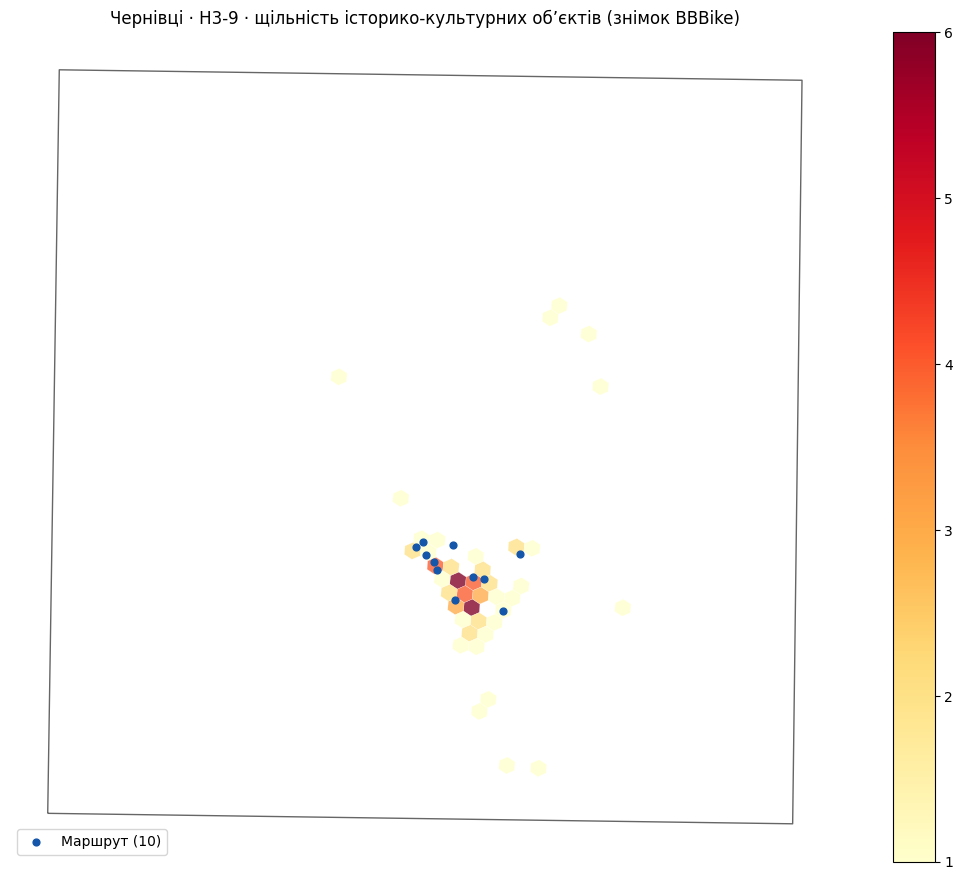

Половина усіх 72 пам’яток у 10 комірках з 41


In [27]:
import h3
from shapely.geometry import Polygon
H3_RES=9
print('Середнє ребро H3-9: %.1f м' % h3.average_hexagon_edge_length(H3_RES,unit='m'))
centers=cand.geometry.representative_point()
cand['h3']=[h3.latlng_to_cell(float(p.y),float(p.x),H3_RES) for p in centers]
dens=cand['h3'].value_counts()
hexes=gpd.GeoDataFrame({'h3':dens.index,'кількість':dens.to_numpy()},
    geometry=[Polygon([(lon,lat) for lat,lon in h3.cell_to_boundary(cell)]) for cell in dens.index],
    crs='EPSG:4326')
fig,ax=plt.subplots(figsize=(11,9))
boundary.to_crs(CRS_METRIC).boundary.plot(ax=ax,color='#666666',linewidth=1.0)
hexes.to_crs(CRS_METRIC).plot(column='кількість',ax=ax,cmap='YlOrRd',legend=True,
                              alpha=.78,edgecolor='white',linewidth=.2)
pts10.to_crs(CRS_METRIC).plot(ax=ax,color='#1456AA',markersize=24,marker='o',label='Маршрут (10)')
ax.set_title('Чернівці · H3-9 · щільність історико-культурних об’єктів (знімок BBBike)')
ax.set_axis_off();ax.legend(loc='lower left');plt.tight_layout()
plt.savefig('lr5_h3_щільність.png',dpi=180,bbox_inches='tight');plt.show()
half=(len(cand)+1)//2
n_half=int(np.searchsorted(np.cumsum(dens.to_numpy()),half,side='left')+1)
print('Половина усіх',len(cand),'пам’яток у',n_half,'комірках з',len(dens))

> **Пастка.** `h3.cell_to_boundary` повертає пари **(lat, lng)**, а
> `shapely.Polygon` чекає **(x, y)**, тобто (lng, lat). Переплутаєте — місто
> опиниться в Індійському океані. Це видно одразу, тому дивіться на карту.

### Питання до звіту

У скількох комірках зосереджено половину всіх пам'яток вашого міста?
Що це говорить про форму маршруту?

---
## 8. Просторове поєднання

### Завдання 8.1

Для кожної точки маршруту знайдіть найближчий заклад із шару `amenities`
(`sjoin_nearest`) і виведіть таблицю з відстанню в метрах.

Нагадування: `sjoin_nearest` рахує в одиницях CRS. У градусах результат буде
безглуздим — перепроєктуйте обидва шари в метричну систему.

In [28]:
# Пошук найближчих amenities в метрах для кожного з 11 пунктів маршруту.
assert len(amenities)>0,'У шарі amenities відсутні об’єкти'
a=amenities[amenities.geometry.notna()&~amenities.geometry.is_empty].copy().reset_index(drop=True)
a['amenity_label']=col_as_str(a,'amenity').fillna('невідомо')
a['amenity_name']=col_as_str(a,'name').fillna(a['amenity_label'])
a=a.to_crs(CRS_METRIC)
a.geometry=a.geometry.representative_point()
p=pts10.to_crs(CRS_METRIC).copy()
p['point_index']=np.arange(len(p))
near=gpd.sjoin_nearest(p,a[['amenity_name','amenity_label','geometry']],
                      how='left',distance_col='distance_m')
near=near.sort_values(['point_index','distance_m','amenity_name'],kind='stable').drop_duplicates('point_index')
NEAREST_AMENITIES=near[['name','amenity_name','amenity_label','distance_m']].copy()
NEAREST_AMENITIES['distance_m']=NEAREST_AMENITIES['distance_m'].round(1)
display(NEAREST_AMENITIES.rename(columns={'name':'точка маршруту',
        'amenity_name':'найближчий заклад','amenity_label':'тип','distance_m':'відстань, м'}))

,точка маршруту,найближчий заклад,тип,"відстань, м"
0,СТАРТ: Чернівці,toilets,toilets,10.7
1,Костел Воздвиження Святого Христа,Гауптвахта,cafe,23.7
2,Музей Володимира Івасюка,О.С.А.,pharmacy,281.7
3,Franz Josef,toilets,toilets,145.6
4,Пам'ятник Сидору Воробкевичу,toilets,toilets,71.7
5,Музей Буковинської Діаспори,toilets,toilets,146.5
6,Музей пожежно-рятувальної справи,Долина Плюс питна вода,drinking_water,56.8
7,Турецька криниця,La Multi ani,restaurant,130.3
8,Пам'ятник Йозефу Главці,cafe,cafe,43.4
9,Зельма Меербаум-Айзінґер,toilets,toilets,191.6


---
## 9. Маршрут на карті

Лінія маршруту — це **геометрія ребер графа**, а не відрізки між пам'ятками.

### Завдання 9.1

Побудуйте карту, на якій **обидві** лінії: справжній маршрут по ребрах і
прямі відрізки між точками. Різниця має бути видно оком.

In [29]:
# Детальна геометрія кожного ребра! Не просто відрізки вузол-вузол.
node_xy=nodes.set_index('osmid')[['x','y']]

def route_coords(tour,ids):
    """Масив (lat,lon) уздовж справжніх OSM LineString у порядку проходження."""
    coords=[]
    for a,b in zip(tour[:-1],tour[1:]):
        path=nx.shortest_path(G,ids[a],ids[b],weight='length')
        for u,v in zip(path[:-1],path[1:]):
            geom=EDGE_GEOM.get((u,v))
            if geom is not None and geom.geom_type=='LineString' and not geom.is_empty:
                xy=list(geom.coords)
                start_xy=(float(G.nodes[u]['x']),float(G.nodes[u]['y']))
                if np.linalg.norm(np.subtract(xy[-1],start_xy))<np.linalg.norm(np.subtract(xy[0],start_xy)):
                    xy.reverse()
            else:
                xy=[(float(G.nodes[u]['x']),float(G.nodes[u]['y'])),
                    (float(G.nodes[v]['x']),float(G.nodes[v]['y']))]
            ll=[(float(y),float(x)) for x,y in xy]
            if coords and ll and coords[-1]==ll[0]:ll=ll[1:]
            coords.extend(ll)
    return coords

order_tour=ex10 # для 10 точок точний оптимальний маршрут
true_polyline=route_coords(order_tour,ids10)
straight_polyline=[(float(pts10.geometry.y.iloc[i]),float(pts10.geometry.x.iloc[i]))
                   for i in order_tour]
lat_c=float(pts10.geometry.y.mean());lon_c=float(pts10.geometry.x.mean())
fmap=folium.Map(location=[lat_c,lon_c],zoom_start=13,tiles=BASEMAP,control_scale=True)
folium.GeoJson(boundary.to_crs('EPSG:4326').to_json(),
               name=('Область даних BBBike (не межа міста)'
                    if 'bounding' in manifest.get('_межа_міста','') else 'Межа Чернівців'),style_function=lambda _: {'color':'#666','weight':1,'fillOpacity':0}).add_to(fmap)
folium.PolyLine(true_polyline,color='#137E6E',weight=5,opacity=.9,
                tooltip='Маршрут пішохідними дорогами').add_to(fmap)
folium.PolyLine(straight_polyline,color='#D8563A',weight=3,opacity=.85,dash_array='8,9',
                tooltip='Прямі відрізки (непішохідний еталон)').add_to(fmap)
for seq,i in enumerate(order_tour[:-1]):
    p=pts10.iloc[i]
    folium.Marker([float(p.geometry.y),float(p.geometry.x)],
                  popup=folium.Popup(html.escape(f'{seq}. {p["name"]}'),max_width=320),
                  tooltip=f'{seq}. {p["name"]}',
                  icon=folium.DivIcon(html=f'<div style="border-radius:50%;width:25px;height:25px;'
                      f'line-height:25px;text-align:center;background:{"#273A72" if i==0 else "#21806A"};'
                      f'color:white;font-weight:bold;border:1px solid white">{seq}</div>')).add_to(fmap)
folium.LayerControl(collapsed=False).add_to(fmap)
fmap.save('lr5_маршрут.html')
print('Збережено lr5_маршрут.html ·',len(true_polyline),'координат уздовж мережі')
assert len(true_polyline)>len(straight_polyline),'Лінія маршруту має бути деталізованішою за прямі сегменти'
display(fmap)

Збережено lr5_маршрут.html · 527 координат уздовж мережі


---
## 10. Результати для лабораторної роботи № 8

Збережіть файл, який ЛР8 прочитає і спробує побити.

In [30]:
result={
    'студент':STUDENT_NAME,'група':GROUP,'номер':LIST_NUMBER,'місто':CITY,
    'джерело':'© OpenStreetMap contributors (ODbL)',
    'походження_знімка':manifest.get('_джерело','невідоме'),
    'критерій_рейтингування':{'ваги':WEIGHTS,'порівняння_перетин_10':overlap},
    'мала_задача':{
        'точок':len(ids10), 'оптимум_м':round(L_opt,1),
        'оптимальний_порядок':[str(pts10['name'].iloc[i]) for i in ex10],
        'найближчий_сусід_м':round(tour_length(D10,nn10),1),
        'двоопт_м':round(tour_length(D10,op10),1)},
    'велика_задача':{
        'точок':len(ids30), 'найближчий_сусід_м':round(L_nn30,1),
        'двоопт_м':round(L_op30,1), 'двоопт_с':round(t_op30,4),
        'оптимальний_невідомий':True,
        'точки':[{'name':str(pts30['name'].iloc[i]),
                  'lat':float(pts30.geometry.y.iloc[i]),
                  'lon':float(pts30.geometry.x.iloc[i])} for i in range(len(pts30))],
        'матриця_віддалей_м':[[None if not np.isfinite(v) else round(float(v),1)
                              for v in row] for row in D30]}}
with open('lr5_результати.json','w',encoding='utf-8') as f:
    json.dump(result,f,ensure_ascii=False,indent=2)
check=json.loads(Path('lr5_результати.json').read_text('utf-8'))
assert len(check['велика_задача']['матриця_віддалей_м'])==len(ids30)
assert len(check['велика_задача']['точки'])==len(ids30)
assert Path('lr5_маршрут.html').stat().st_size>1000
print('Збережено lr5_результати.json (%.1f КБ)' % (Path('lr5_результати.json').stat().st_size/1024))

Збережено lr5_результати.json (21.1 КБ)


---
## 11. Звіт

Відповіді пишіть просто в наступній комірці, числами зі своїх обчислень.

1. **Скільки об'єктів ви відкинули** на кроці 2 і за яким правилом? Чи погодились
   би ви віддати цей фільтр замовнику без пояснень?
2. **Які сигнали ввійшли у ваш рейтинг і з якими вагами?** Чому саме так?
3. **Скільки об'єктів збіглося** у ваших двох рейтингах із десяти? Що це
   означає для слова «найкращі»?
4. **Який у вас коефіцієнт обходу** і чи типовий він? Якщо ні — що в місті
   його пояснює?
5. **На скільки відсотків** найближчий сусід гірший за точний розв'язок?
   Чи здивувало вас це число?
6. **Чому точний розв'язок на 30 точках недоступний?** Назвіть конкретну
   величину, яка цьому заважає.
7. **Що у ваших даних виявилось неправильним** — дублікати, пропущені назви,
   об'єкти не на місці? Як ви з цим вчинили?

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-помічником, у яких саме місцях і як перевіряли
отриманий код. Використання дозволене; **неперевірене** використання — ні.

In [33]:
percentage_nn=(tour_length(D10,nn10)/L_opt-1)*100
percentage_2opt=(tour_length(D10,op10)/L_opt-1)*100
n_excluded=FILTER_STATS['загалом']-FILTER_STATS['залишилось']
dup_examples='; '.join(f'{a} / {b}' for a,b,_ in duplicate_log[:3]) if duplicate_log else 'явних повторів за назвою/Wikidata не виявлено'
hist_comp=pd.DataFrame(comparison) if comparison else pd.DataFrame()
if not hist_comp.empty and 'прискорення, разів' in hist_comp:
    acceleration=float(np.median(hist_comp['прискорення, разів'].dropna()))
    comp_txt=f'Медіанне прискорення читання на шарах з історією завантаження: {acceleration:.1f} раза.'
else:
    comp_txt='Відсутній журнал першого мережевого запиту; числове прискорення не вигадується.'
report_lines=[
 f'ЛАБОРАТОРНА РОБОТА №5 — {STUDENT_NAME}, {GROUP}, варіант {LIST_NUMBER}: {CITY}',
 'Мета: відбір і ранжування історико-культурних об’єктів, порівняння методів TSP та візуалізація пішохідних маршрутів.',
 '',
 '1. Відбір об’єктів. Із %d записів відкинуто %d; не пройшли історико-туристичні теги: %d;'
 ' бракує назви/геометрії серед релевантних: %d. Відібрано %d кандидатів. Замовникові необхідно пояснити правила,'
 ' оскільки інший набір тегів змінює результат.' %
 (FILTER_STATS['загалом'],n_excluded,FILTER_STATS['без_потрібних_тегів'],
  FILTER_STATS['без_назви_або_геометрії'],FILTER_STATS['залишилось']),
 '',
 '2. Рейтинг. Використано Wikidata/Wikipedia (35%), кількість мов назви (25%), історичний тег (20%),'
 ' тип museum/gallery (15%), площу (5%). Перші два сигнали відбивають зовнішнє визнання та відвідуваність,'
 ' історичність і туристичний тип характеризують зміст, площа — слабкий допоміжний сигнал.'
 ' Масштабування числових полів: процентильний ранг [0,1].',
 '',
 f'3. Порівняння: збіг {overlap} з 10 пам’яток між комплексним рейтингом та рейтингом за площею.'
 ' Отже, «найкращі» залежить від мети й ваг оцінювання, а не задається самим OSM.',
 '',
 f'4. Коефіцієнт обходу: {DETOUR10:.3f} для малого і {DETOUR30:.3f} для великого набору.'
 + (' Малий коефіцієнт потрапляє в орієнтовний міський діапазон 1,2–1,6.'
    if 1.2<=DETOUR10<=1.6 else
    ' Відхилення від орієнтовного 1,2–1,6 потребує перевірки особливостей доріг, бар’єрів і прив’язки.'),
 '',
 f'5. Для 10 пам’яток Held–Karp: {L_opt:.1f} м; Nearest Neighbour: {tour_length(D10,nn10):.1f} м'
 f' (гірше на {percentage_nn:.2f}%); 2-opt: {tour_length(D10,op10):.1f} м (гірше на {percentage_2opt:.2f}%).'
 ' Жадібний вибір не враховує вартість завершення туру; 2-opt прибирає локально невигідні ділянки.',
 '',
 f'6. Для 30 пам’яток плюс вокзал Held–Karp потребував би приблизно '
 f'{resource_table.iloc[-1]["пам’ять за 8 байт/клітину, ГБ"]:.1f} ГБ лише на значення DP'
 ' (а в Python — більше). Число станів зростає експоненційно.'
 f' Тому для {N_LARGE} пам’яток використано 2-opt: {L_op30:.1f} м за {t_op30:.4f} с;',
 '',
 f'7. Якість OSM. Знайдено {len(duplicate_log)} очевидних близьких повторів у кандидатах,'
 f' {len(close)} близьких пар у фінальному топі; приклади: {dup_examples}.'
 f' Збережено лише різні за назвою/Wikidata об’єкти. Прив’язка 10 точок до мережі:'
 f' медіана {CHECK10["медіана_м"]:.1f} м, максимум {CHECK10["максимум_м"]:.1f} м;'
 ' для надмірного зміщення потрібна додаткова перевірка на карті.',
 '',
 f'Додатково: H3 рівня 9: половина {len(cand)} пам’яток у {n_half} з {len(dens)} зайнятих комірок.'
 ' Це дозволяє судити, наскільки маршрут концентрується в історичному центрі.',
 f'Порівняння доступу до даних. {comp_txt}',
 ('Географічне охоплення: '+manifest.get('_межа_міста','не уточнено')+'. '
  'Покриття шляхів наближене: '+manifest.get('_похибка','пішохідна мережа OSM')+'. '),
 'Джерело знімка: '+manifest.get('_джерело', 'Overpass API через osmnx')+'. ' 
 '',
 'Декларація про використання ШІ: під час підготовки програмної частини використовувався'
 ' chatGPT для написання/редагування функцій та перевірок отриманих результатів; результати мають'
 ' підтверджуватись повторним виконанням ноутбука й контролем CRS, унікальності вузлів,'
 ' замкненості маршруту і графічної геометрії.',
 '',
 'Джерело геоданих: © OpenStreetMap contributors. Ліцензія ODbL.'
]
REPORT='\n'.join(report_lines)
print(REPORT)
Path('lr5_звіт.txt').write_text(REPORT,encoding='utf-8')

ЛАБОРАТОРНА РОБОТА №5 — Єдинець Євген, ШІ-31, варіант 6: Чернівці, Україна
Мета: відбір і ранжування історико-культурних об’єктів, порівняння методів TSP та візуалізація пішохідних маршрутів.

1. Відбір об’єктів. Із 93 записів відкинуто 21; не пройшли історико-туристичні теги: 0; бракує назви/геометрії серед релевантних: 21. Відібрано 72 кандидатів. Замовникові необхідно пояснити правила, оскільки інший набір тегів змінює результат.

2. Рейтинг. Використано Wikidata/Wikipedia (35%), кількість мов назви (25%), історичний тег (20%), тип museum/gallery (15%), площу (5%). Перші два сигнали відбивають зовнішнє визнання та відвідуваність, історичність і туристичний тип характеризують зміст, площа — слабкий допоміжний сигнал. Масштабування числових полів: процентильний ранг [0,1].

3. Порівняння: збіг 3 з 10 пам’яток між комплексним рейтингом та рейтингом за площею. Отже, «найкращі» залежить від мети й ваг оцінювання, а не задається самим OSM.

4. Коефіцієнт обходу: 1.289 для малого і 1.212 д

2783

### Фінальна перевірка

Після першого успішного збору даних виконайте **Kernel → Restart Kernel and Run All Cells**.
Перевіряються: варіант, виходи в GeoParquet, унікальність вузлів, зв’язність графа, обидва маршрути,
нерівності оптимальності, збереження JSON/HTML, повторне читання з локального знімка. 

Для повної числової перевірки знімка потрібні реальні шари міста Чернівці; дані іншого міста не є заміною.

In [32]:
assert CITY=='Чернівці, Україна'
assert all(p.suffix=='.parquet' for p in Path(OUT).glob('*.parquet'))
assert all(x['спосіб']=='знімок' for x in COST.values()) or any(x['спосіб']=='живий запит' for x in COST.values())
assert np.isfinite(D10).all() and np.isfinite(D30).all()
assert 0<=overlap<=10
assert 0<=min(percentage_nn,percentage_2opt)+1e-6
assert Path('lr5_маршрут.html').is_file()
assert Path('lr5_результати.json').is_file()
assert Path('lr5_h3_щільність.png').is_file()
print('Фінальні інваріанти перевірено; перевірте також візуально HTML-карту.')

Фінальні інваріанти перевірено; перевірте також візуально HTML-карту.
